cell 1 imports

In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


cell 2
dataset path

In [25]:
dataset_path = r"D:\Deep-learning\Plant Disease Classifier\PlantVillage\PlantVillage"

classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of classes:", len(classes))
print("\nClasses:")

for i, class_name in enumerate(classes):
    print(i, "→", class_name)

Number of classes: 15

Classes:
0 → Pepper__bell___Bacterial_spot
1 → Pepper__bell___healthy
2 → Potato___Early_blight
3 → Potato___Late_blight
4 → Potato___healthy
5 → Tomato_Bacterial_spot
6 → Tomato_Early_blight
7 → Tomato_Late_blight
8 → Tomato_Leaf_Mold
9 → Tomato_Septoria_leaf_spot
10 → Tomato_Spider_mites_Two_spotted_spider_mite
11 → Tomato__Target_Spot
12 → Tomato__Tomato_YellowLeaf__Curl_Virus
13 → Tomato__Tomato_mosaic_virus
14 → Tomato_healthy


cell3:
    create clean dataframe

In [26]:
data = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        if os.path.isfile(image_path):

            data.append({
                "image_path": image_path,
                "class": class_name
            })

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)

Dataset shape: (20638, 2)


cell4:
encode labels

In [27]:
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["class"])

print(df.head())
print("\nNumber of labels:", df["label"].nunique())

                                          image_path  \
0  D:\Deep-learning\Plant Disease Classifier\Plan...   
1  D:\Deep-learning\Plant Disease Classifier\Plan...   
2  D:\Deep-learning\Plant Disease Classifier\Plan...   
3  D:\Deep-learning\Plant Disease Classifier\Plan...   
4  D:\Deep-learning\Plant Disease Classifier\Plan...   

                           class  label  
0  Pepper__bell___Bacterial_spot      0  
1  Pepper__bell___Bacterial_spot      0  
2  Pepper__bell___Bacterial_spot      0  
3  Pepper__bell___Bacterial_spot      0  
4  Pepper__bell___Bacterial_spot      0  

Number of labels: 15


cell5:
    check class distribution

In [28]:
class_counts = df["class"].value_counts().sort_index()

print(class_counts)

class
Pepper__bell___Bacterial_spot                   997
Pepper__bell___healthy                         1478
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Potato___healthy                                152
Tomato_Bacterial_spot                          2127
Tomato_Early_blight                            1000
Tomato_Late_blight                             1909
Tomato_Leaf_Mold                                952
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato__Target_Spot                            1404
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato__Tomato_mosaic_virus                     373
Tomato_healthy                                 1591
Name: count, dtype: int64


cell6:
    train/test/split

In [29]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (16510, 3)
Validation: (2064, 3)
Test: (2064, 3)


cell7:
    dataset configuration

In [30]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(classes)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 32
Classes: 15


cell8:
    Create Tensorflow dataset

In [31]:
def create_dataset(dataframe, shuffle=False):

    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            IMG_SIZE
        )

        image = tf.cast(
            image,
            tf.float32
        )

        image = tf.keras.applications.mobilenet_v2.preprocess_input(
            image
        )

        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=1
    )

    if shuffle:
        dataset = dataset.shuffle(
            1000,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(1)

    return dataset

cell9 :
   build dataset

In [32]:
train_ds = create_dataset(
    train_df,
    shuffle=True
)

val_ds = create_dataset(
    val_df
)

test_ds = create_dataset(
    test_df
)

print("Datasets created successfully.")

Datasets created successfully.


Cell 10 — VERY IMPORTANT shape check

In [33]:
images, labels = next(iter(train_ds))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (32, 224, 224, 3)
Labels shape: (32,)


In [34]:
for batch_images, batch_labels in train_ds.take(2):
    print(batch_images.shape, batch_labels.shape)

print("Dataset pipeline working.")

(32, 224, 224, 3) (32,)
(32, 224, 224, 3) (32,)
Dataset pipeline working.


cell 11:
    check image visualization

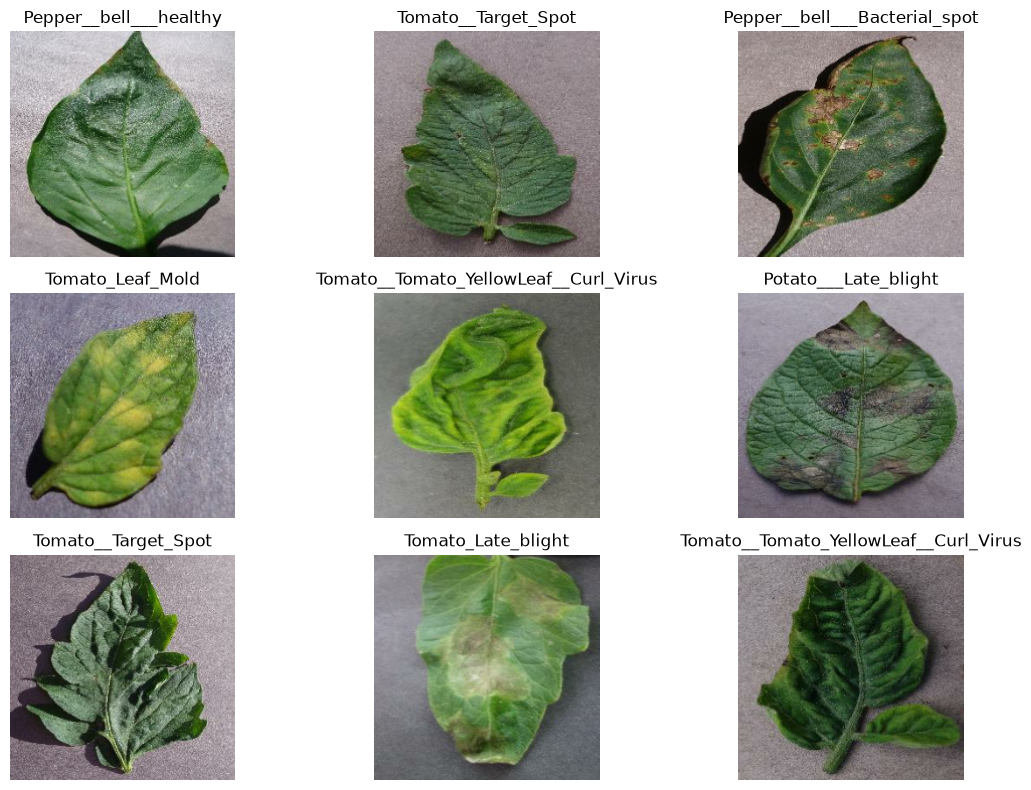

In [35]:
plt.figure(figsize=(12, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    image = (images[i].numpy() + 1) / 2

    plt.imshow(image)
    plt.title(classes[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

cell 12:
    Data Augmentation

In [36]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.2)
])

print("Data augmentation ready.")

Data augmentation ready.


cell 13:
    MobileNetV2

In [37]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("Base model trainable:", base_model.trainable)

Base model trainable: False


cell 14:
    Build model

In [38]:
model = tf.keras.Sequential([
    data_augmentation,

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

print("Model created.")

Model created.


cell 15:
    Build + summary

In [39]:
model.build((None, 224, 224, 3))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,424,399 (9.25 MB)

 Trainable params: 166,159 (649.06 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

cell 16:
    Compile

In [40]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


cell 17:
    callbacks

In [41]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

print("Callbacks ready.")

Callbacks ready.


cell 18:
    Final Training

In [42]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10


d:\Deep-learning\Plant Disease Classifier\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


516/516 ━━━━━━━━━━━━━━━━━━━━ 506s 960ms/step - accuracy: 0.7881 - loss: 0.6685 - val_accuracy: 0.8600 - val_loss: 0.4135 - learning_rate: 0.0010
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 557s 1s/step - accuracy: 0.8697 - loss: 0.4039 - val_accuracy: 0.8886 - val_loss: 0.3402 - learning_rate: 0.0010
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 542s 1s/step - accuracy: 0.8844 - loss: 0.3550 - val_accuracy: 0.8813 - val_loss: 0.3507 - learning_rate: 0.0010
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 596s 1s/step - accuracy: 0.8881 - loss: 0.3375 - val_accuracy: 0.8721 - val_loss: 0.3646 - learning_rate: 0.0010
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 565s 1s/step - accuracy: 0.9047 - loss: 0.2896 - val_accuracy: 0.8828 - val_loss: 0.3444 - learning_rate: 5.0000e-04


cell 19:
    Training graph

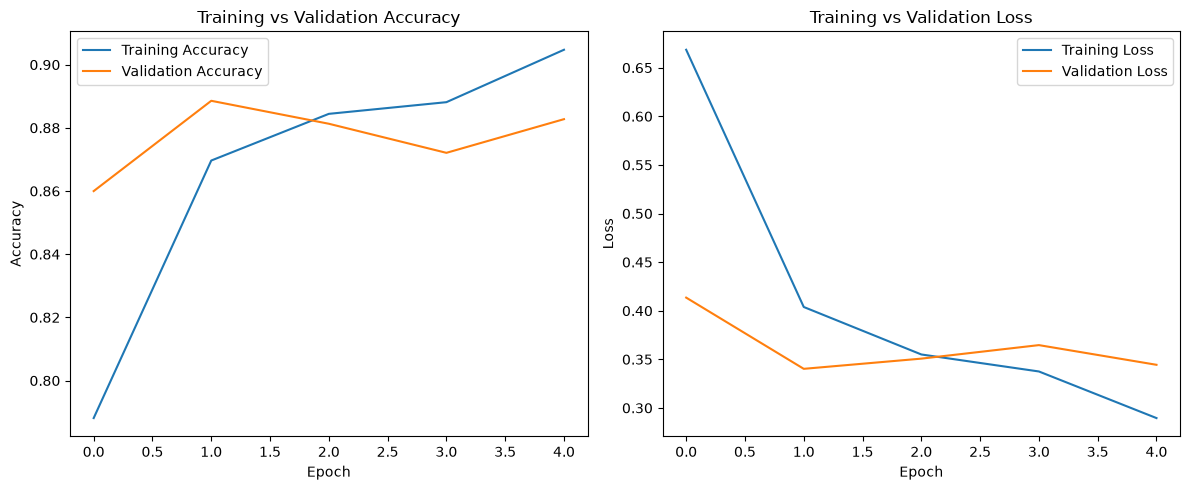

In [43]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

cell 20:
    Test accuracy

In [44]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

65/65 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.8905 - loss: 0.3277
Test Loss: 0.3276878893375397
Test Accuracy: 0.8905038833618164


cell 21:
    dataset was imbalance check each disease class precision, recall, F1 score

In [45]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images_batch, labels_batch in test_ds:

    predictions = model.predict(
        images_batch,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels_batch.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.97      0.98      0.98       100
                     Pepper__bell___healthy       0.99      0.97      0.98       148
                      Potato___Early_blight       0.95      0.96      0.96       100
                       Potato___Late_blight       0.87      0.94      0.90       100
                           Potato___healthy       0.80      0.80      0.80        15
                      Tomato_Bacterial_spot       0.79      0.94      0.86       213
                        Tomato_Early_blight       0.88      0.42      0.57       100
                         Tomato_Late_blight       0.94      0.92      0.93       191
                           Tomato_Leaf_Mold       0.91      0.87      0.89        95
                  Tomato_Septoria_leaf_spot       0.82      0.82      0.82       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.87      0.90

cell 22:
    confusion matrix

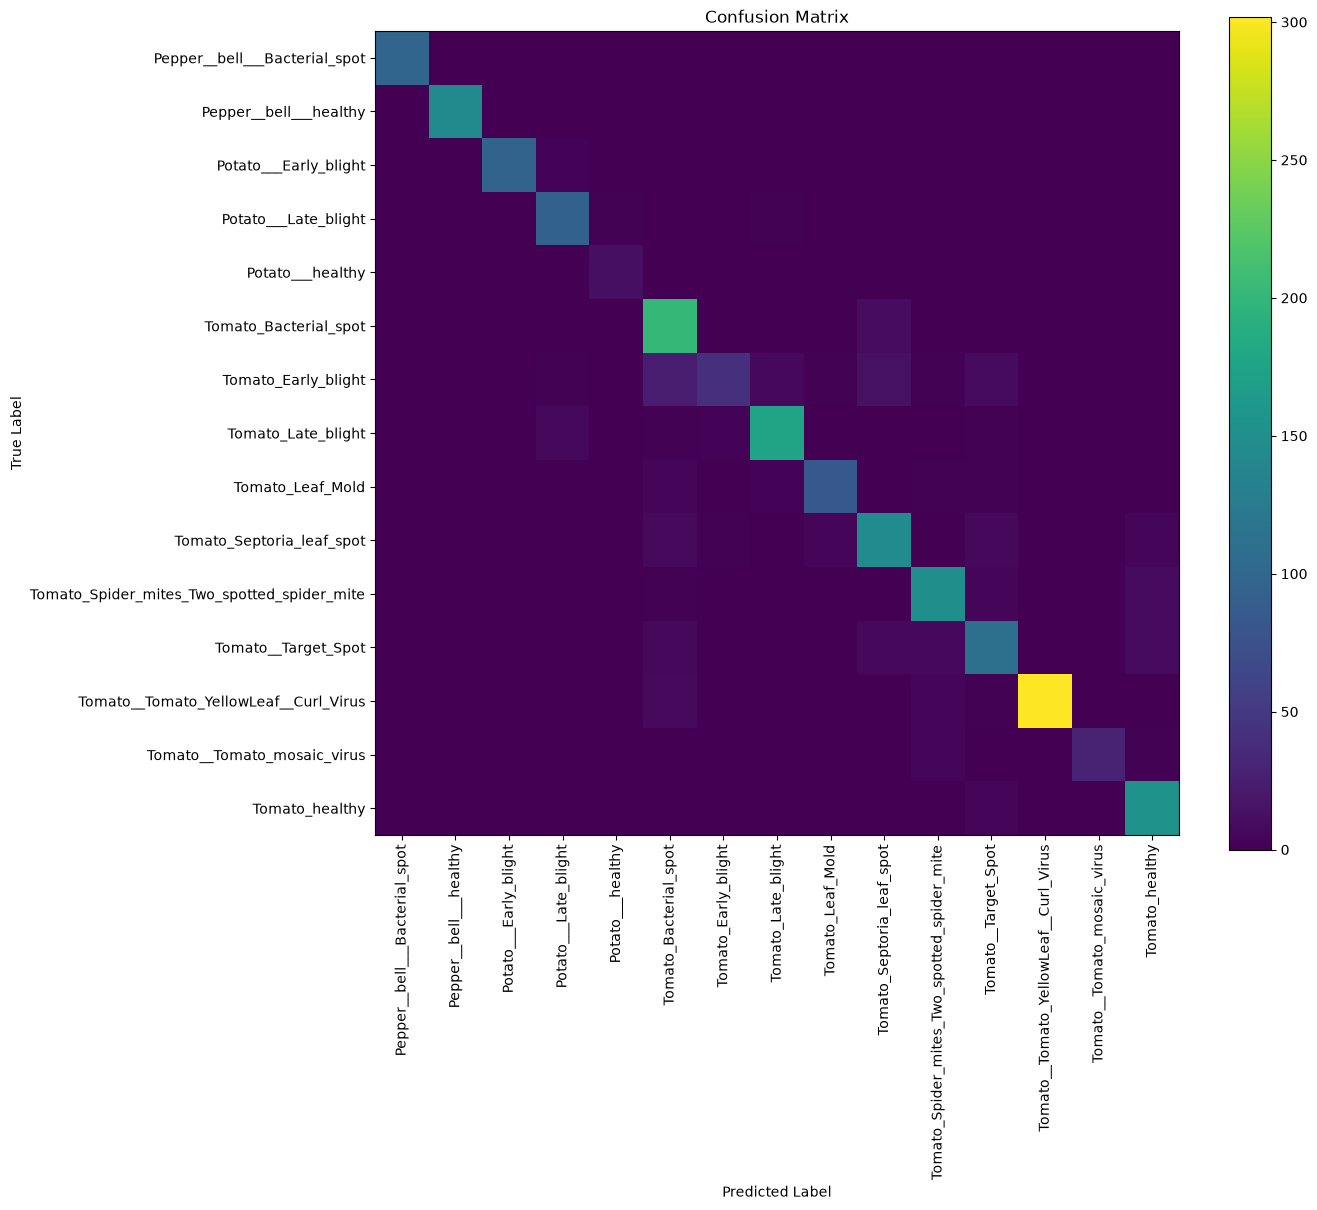

In [46]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    classes,
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    classes
)

plt.tight_layout()
plt.show()

In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[ 98   1   1   0   0   0   0   0   0   0   0   0   0   0   0]
 [  1 144   0   0   1   0   0   0   0   0   0   1   0   0   1]
 [  0   0  96   3   0   0   0   0   0   1   0   0   0   0   0]
 [  0   0   1  94   2   0   1   2   0   0   0   0   0   0   0]
 [  0   1   0   0  12   0   0   0   0   0   1   0   0   0   1]
 [  0   0   0   1   0 201   0   0   0  10   0   1   0   0   0]
 [  0   0   1   2   0  23  42   6   2  13   2   9   0   0   0]
 [  0   0   0   7   0   2   3 176   0   0   1   2   0   0   0]
 [  0   0   0   0   0   5   0   3  83   0   2   2   0   0   0]
 [  1   0   1   1   0   8   2   0   4 146   1   7   1   1   4]
 [  0   0   0   0   0   2   0   0   1   0 150   5   0   0   9]
 [  0   0   1   0   0   7   0   0   0   7   6 111   0   0   9]
 [  1   0   0   0   0   8   0   1   0   0   5   2 302   1   1]
 [  0   0   0   0   0   0   0   0   1   1   4   0   0  29   2]
 [  0   0   0   0   0   0   0   0   0   0   0   5   0   0 154]]


cell 23:
    Sample Predictions + Confidence

In [48]:
sample_images, sample_labels = next(iter(test_ds))

predictions = model.predict(
    sample_images,
    verbose=0
)

for i in range(10):

    predicted_index = np.argmax(predictions[i])
    confidence = np.max(predictions[i]) * 100

    actual_index = sample_labels[i].numpy()

    print(f"\nImage {i + 1}")
    print("Actual    :", classes[actual_index])
    print("Predicted :", classes[predicted_index])
    print("Confidence:", f"{confidence:.2f}%")


Image 1
Actual    : Tomato__Tomato_YellowLeaf__Curl_Virus
Predicted : Tomato__Tomato_YellowLeaf__Curl_Virus
Confidence: 99.21%

Image 2
Actual    : Tomato_Late_blight
Predicted : Tomato_Late_blight
Confidence: 91.31%

Image 3
Actual    : Tomato_Bacterial_spot
Predicted : Tomato_Bacterial_spot
Confidence: 83.30%

Image 4
Actual    : Pepper__bell___healthy
Predicted : Pepper__bell___healthy
Confidence: 99.33%

Image 5
Actual    : Tomato__Tomato_YellowLeaf__Curl_Virus
Predicted : Tomato__Tomato_YellowLeaf__Curl_Virus
Confidence: 99.82%

Image 6
Actual    : Tomato_Septoria_leaf_spot
Predicted : Tomato_Septoria_leaf_spot
Confidence: 99.68%

Image 7
Actual    : Tomato_Early_blight
Predicted : Tomato_Bacterial_spot
Confidence: 93.74%

Image 8
Actual    : Tomato_Late_blight
Predicted : Tomato_Late_blight
Confidence: 99.72%

Image 9
Actual    : Tomato__Tomato_YellowLeaf__Curl_Virus
Predicted : Tomato__Tomato_YellowLeaf__Curl_Virus
Confidence: 100.00%

Image 10
Actual    : Tomato_Bacterial_spot

cell 24:
    save model

In [49]:
import os

os.makedirs("model", exist_ok=True)

model.save("model/plant_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


cell 25:
    save classes

In [50]:
import json

with open("model/classes.json", "w") as f:
    json.dump(
        label_encoder.classes_.tolist(),
        f
    )

print("Classes saved successfully!")

Classes saved successfully!
